# Grammar Scoring Engine for Spoken English — SHL Hiring Assessment 2026

**Task:** given a 45–60 s audio clip, predict the MOS grammar score (0–5).
**Metric:** RMSE (leaderboard) and Pearson correlation.

## Report (summary)

**Approach in one line:** turn each clip into a few strong, interpretable signals — *what was said* (transcript-based grammar features + an LLM rubric judge) and *how it was said* (speech-model embeddings) — then combine them with simple regressors (Ridge + LightGBM), validated with 5-fold cross-validation.

| Stage | What | Why |
|---|---|---|
| 1. Preprocessing | Resample all audio to 16 kHz mono (librosa). | Whisper and WavLM both expect 16 kHz. |
| 2. Transcription | `transcribe.py`: Whisper large-v3, no VAD, no context conditioning. | Keep hesitations / errors; they are the signal. |
| 3. Text features | 8 fluency features + 4 CoLA grammaticality features. | Cheap, interpretable. |
| 4. LLM judge | One rubric score (1–5) per transcript (`llm_score.py`, same prompt for every judge). | Directly applies the SHL rubric. |
| 5. Audio features | `audio_embed.py`: frozen WavLM-large, mean+std pooled, best layers chosen by CV → Ridge → one out-of-fold feature. | Audio carries errors the transcript hides (ASR "cleans up" grammar). |
| 6. Fine-tuned audio | `finetune.py`: WavLM fine-tuned to regress the score (30 s crops, 10-fold) → out-of-fold feature. | Learns task-specific acoustic cues. |
| 7. Final model | Ridge + LightGBM on the stacked features, averaged, clipped to [0, 5]. | 769 samples → small, regularised models. |

**Results (5-fold CV on train, see Section 6):** RMSE ≈ 0.46, Pearson r ≈ 0.93.

The heavy steps (Whisper, LLM scoring, WavLM extraction / fine-tuning) are separate scripts whose outputs are cached as CSV/NPZ files; this notebook loads those caches so it runs in minutes. Run order is in `README.md`.


In [1]:
import re
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
from pathlib import Path
from scipy.stats import pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA = Path('data/Dataset_Final')
SEED = 0
kf = KFold(5, shuffle=True, random_state=SEED)
sns.set_theme(style='whitegrid')

def rmse(p, y): return float(np.sqrt(((p - y) ** 2).mean()))
def report(name, p, y):
    p = np.clip(p, 0, 5)
    return {'model': name, 'RMSE': round(rmse(p, y), 3), 'Pearson r': round(pearsonr(p, y)[0], 3)}

## 1. Data

train 769  test 216
NB: train/ and test/ reuse the same file names for different recordings, so every join below uses (split, filename).


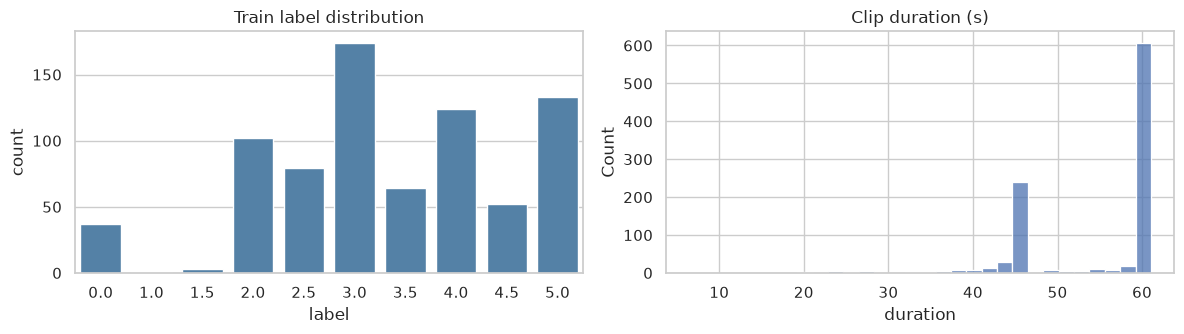

In [2]:
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')[['filename']]   # test.csv labels are placeholders
y = train.label.values
print(f'train {len(train)}  test {len(test)}')
print('NB: train/ and test/ reuse the same file names for different recordings, so every join below uses (split, filename).')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.countplot(x=train.label, ax=ax[0], color='steelblue'); ax[0].set_title('Train label distribution')
t = pd.read_csv('transcripts.csv')
sns.histplot(t.duration, bins=30, ax=ax[1]); ax[1].set_title('Clip duration (s)')
plt.tight_layout(); plt.show()

Labels are on a 0–5 half-point scale, mostly 2–5. The **37 clips scored 0** sit outside the 1–5 rubric: listening/reading them shows silent, off-topic or unusable recordings (e.g. Whisper hallucinating *"Thanks for watching!"* on near-silence). The `no_speech_prob` and audio features let the model recognise them.

## 2. Transcripts (Whisper large-v3)

In [3]:
def split_join(df, split, other, cols):
    o = other[other.split == split][['filename', *cols]]
    out = df[['filename']].merge(o, on='filename', how='left')
    assert len(out) == len(df), 'join changed row count'
    return out

tr = train.merge(t[t.split == 'train'], on='filename')
te = test.merge(t[t.split == 'test'], on='filename')
tr.text, te.text = tr.text.fillna(''), te.text.fillna('')
tr[['filename', 'label', 'text']].head(5)

,filename,label,text
0,audio_192.wav,3.0,"The playground is very, very beautiful and fun..."
1,audio_436.wav,3.0,The scene of a school playground. Our playgrou...
2,audio_447.wav,3.5,my favorite place to visit is the beach I love...
3,audio_126.wav,2.0,Once upon a time we with five friends went on ...
4,audio_61.wav,2.0,"Well, when I was a child, I remember I went to..."


## 3. Text features

**Fluency features (8):** word count, speech rate (words/s), sentence count, mean sentence length, filler rate (*uh, um, ah, like, so*), Whisper mean log-prob (ASR confidence), Whisper no-speech probability, type–token ratio (vocabulary variety).

**CoLA features (4):** each sentence is scored by `textattack/roberta-base-CoLA`, a classifier trained on the Corpus of Linguistic Acceptability (grammatical vs. ungrammatical). Per clip: mean, min, share > 0.5, median.

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


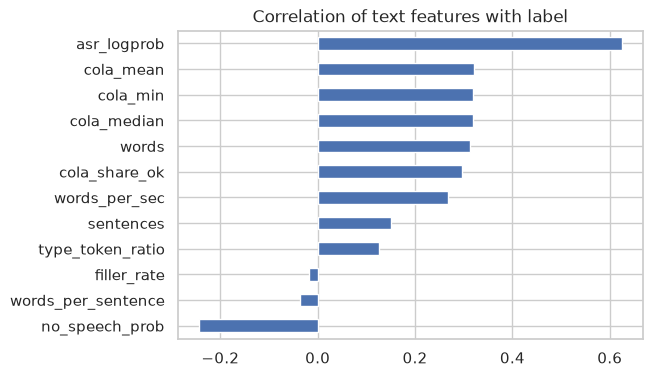

In [4]:
def fluency(df):
    w = df.text.str.split().str.len().fillna(0)
    sents = df.text.str.count(r'[.?!]') + 1
    return pd.DataFrame({
        'words': w, 'words_per_sec': w / df.duration, 'sentences': sents, 'words_per_sentence': w / sents,
        'filler_rate': df.text.str.lower().str.count(r'\b(uh|um|ah|like|so)\b') / (w + 1),
        'asr_logprob': df.avg_logprob, 'no_speech_prob': df.no_speech_prob,
        'type_token_ratio': df.text.apply(lambda s: len(set(s.lower().split())) / (len(s.split()) + 1)),
    })

from transformers import pipeline
cola = pipeline('text-classification', model='textattack/roberta-base-CoLA', top_k=None, truncation=True, device=-1)
def cola_feats(df):
    rows = []
    for s in df.text:
        sents = [x for x in re.split(r'(?<=[.?!])\s+', s) if len(x.split()) > 2] or [s or '.']
        p = np.array([{d['label']: d['score'] for d in r}['LABEL_1'] for r in cola(sents, batch_size=32)])
        rows.append([p.mean(), p.min(), (p > 0.5).mean(), np.median(p)])
    return pd.DataFrame(rows, columns=['cola_mean', 'cola_min', 'cola_share_ok', 'cola_median'])

F_tr = pd.concat([fluency(tr), cola_feats(tr)], axis=1)
F_te = pd.concat([fluency(te), cola_feats(te)], axis=1)
F_tr.corrwith(pd.Series(y)).sort_values().plot.barh(figsize=(6, 4), title='Correlation of text features with label'); plt.show()

## 4. LLM rubric judge

`llm_score.py` sends each transcript with the SHL rubric to an LLM and asks for a 1–5 score (JSON). Three judges were tried with the identical prompt:

| Judge | Coverage | Raw Pearson r with labels (train) |
|---|---|---|
| Claude (Opus 5.5) | all 985 | **0.675** |
| Groq `gpt-oss-120b` | partial (free-tier rate limits) | ≈0.47 |
| Gemini 2.5 Flash | 20 clips (free-tier daily quota) | — |

Only the Claude score is used. **Provenance note:** the API account had no credits, so the Claude scores were produced by Claude Opus 5.5 in a Claude Code session, applying the same rubric prompt blind (without seeing any train labels). `python llm_score.py claude` regenerates them via the API; values may differ slightly between runs.

Pearson r (Claude score vs label): 0.675


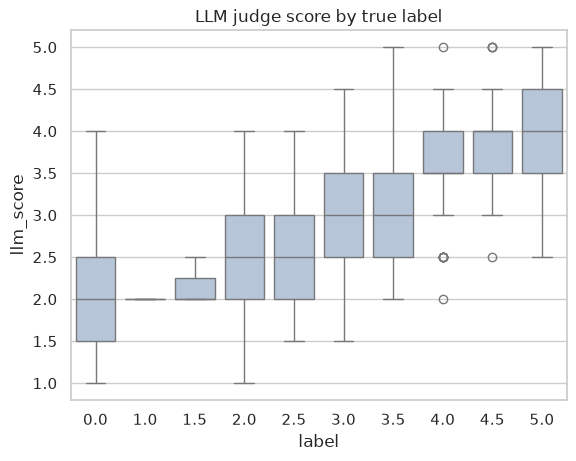

In [5]:
cl = pd.read_csv('llm_scores_claude.csv')
F_tr['llm_score'] = split_join(tr, 'train', cl, ['llm_score']).llm_score.values
F_te['llm_score'] = split_join(te, 'test', cl, ['llm_score']).llm_score.values
print('Pearson r (Claude score vs label):', round(pearsonr(F_tr.llm_score, y)[0], 3))
sns.boxplot(x=train.label, y=F_tr.llm_score, color='lightsteelblue'); plt.title('LLM judge score by true label'); plt.show()

## 5. Audio features

**Frozen WavLM-large** (`audio_embed.py`): every hidden layer is mean- and std-pooled over time. A per-layer CV sweep showed the middle-upper layers (13, 14, 19, 21) work best, matching the usual finding that those layers carry the most linguistic information. Their average (2048-d) goes into a Ridge model whose **out-of-fold** prediction becomes a single feature, which keeps 2048 dimensions from swamping 13 hand-made ones and avoids leakage.

**Fine-tuned WavLM-base-plus** (`finetune.py`): the transformer layers are trained to regress the score (learned layer mix + linear head, 30 s random crops, MSE, 14 epochs, 10 folds). Test predictions average the 10 fold models over 4 crops per clip. These settings came from an experiment: the first run (15 s crops, 5 folds, 12 epochs) reached OOF RMSE 0.535. Longer crops let the model hear more of each answer, and 10 folds let each model train on 90% of the data, giving OOF RMSE 0.519. A second seed of the first setup scored 0.569, so seed-to-seed variance is real at this data size.

In [6]:
z = np.load('audio_large.npz', allow_pickle=True)
A = pd.DataFrame(z['emb'][:, [13, 14, 19, 21]].astype(np.float32).mean(1))
A['filename'], A['split'] = z['filename'], z['split']
def audio(df, split):
    return df[['filename']].merge(A[A.split == split], on='filename').drop(columns=['filename', 'split']).values
A_tr, A_te = audio(tr, 'train'), audio(te, 'test')

ridge = lambda: make_pipeline(StandardScaler(), RidgeCV(np.logspace(-1, 6, 30)))
F_tr['wavlm_ridge'] = cross_val_predict(ridge(), A_tr, y, cv=KFold(5, shuffle=True, random_state=1))
F_te['wavlm_ridge'] = ridge().fit(A_tr, y).predict(A_te)

ft = pd.read_csv('finetune_preds_base-plus_f10c30e14.csv')  # FOLDS=10 CROP_S=30 EPOCHS=14
F_tr['wavlm_finetuned'] = split_join(tr, 'train', ft, ['ft_pred']).ft_pred.values
F_te['wavlm_finetuned'] = split_join(te, 'test', ft, ['ft_pred']).ft_pred.values
assert not F_tr.isna().any().any() and not F_te.isna().any().any()
F_tr.shape, F_te.shape

((769, 15), (216, 15))

## 6. Model and evaluation (5-fold CV)

Ablation: each row adds one feature group. All numbers are out-of-fold on the 769 training clips.

In [7]:
gbm = lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=20, verbose=-1, random_state=SEED)
groups = {
    'fluency (8)': list(fluency(tr.head(1)).columns),
    '+ CoLA (4)': ['cola_mean', 'cola_min', 'cola_share_ok', 'cola_median'],
    '+ LLM judge': ['llm_score'],
    '+ WavLM-large (frozen)': ['wavlm_ridge'],
    '+ WavLM fine-tuned': ['wavlm_finetuned'],
}
rows, cols = [], []
for name, g in groups.items():
    cols += g
    rows.append(report(name, cross_val_predict(ridge(), F_tr[cols], y, cv=kf), y))
oof_ridge = cross_val_predict(ridge(), F_tr[cols], y, cv=kf)
oof_gbm = cross_val_predict(gbm(), F_tr[cols], y, cv=kf)
rows += [report('LightGBM, all', oof_gbm, y), report('Final: Ridge + LightGBM average', (oof_ridge + oof_gbm) / 2, y)]
results = pd.DataFrame(rows); results

,model,RMSE,Pearson r
0,fluency (8),0.857,0.722
1,+ CoLA (4),0.843,0.733
2,+ LLM judge,0.784,0.774
3,+ WavLM-large (frozen),0.504,0.914
4,+ WavLM fine-tuned,0.466,0.927
5,"LightGBM, all",0.483,0.921
6,Final: Ridge + LightGBM average,0.464,0.927


### Training-data RMSE (required)
Final model fitted on all 769 training clips and evaluated on those same clips (in-sample), shown next to the honest out-of-fold estimate.

In [8]:
final_ridge, final_gbm = ridge().fit(F_tr[cols], y), gbm().fit(F_tr[cols], y)
train_pred = np.clip((final_ridge.predict(F_tr[cols]) + final_gbm.predict(F_tr[cols])) / 2, 0, 5)
oof_final = np.clip((oof_ridge + oof_gbm) / 2, 0, 5)
print(f'Training RMSE (in-sample):   {rmse(train_pred, y):.4f}   Pearson r {pearsonr(train_pred, y)[0]:.4f}')
print(f'Cross-validated RMSE (OOF):  {rmse(oof_final, y):.4f}   Pearson r {pearsonr(oof_final, y)[0]:.4f}')

Training RMSE (in-sample):   0.3765   Pearson r 0.9532
Cross-validated RMSE (OOF):  0.4645   Pearson r 0.9271


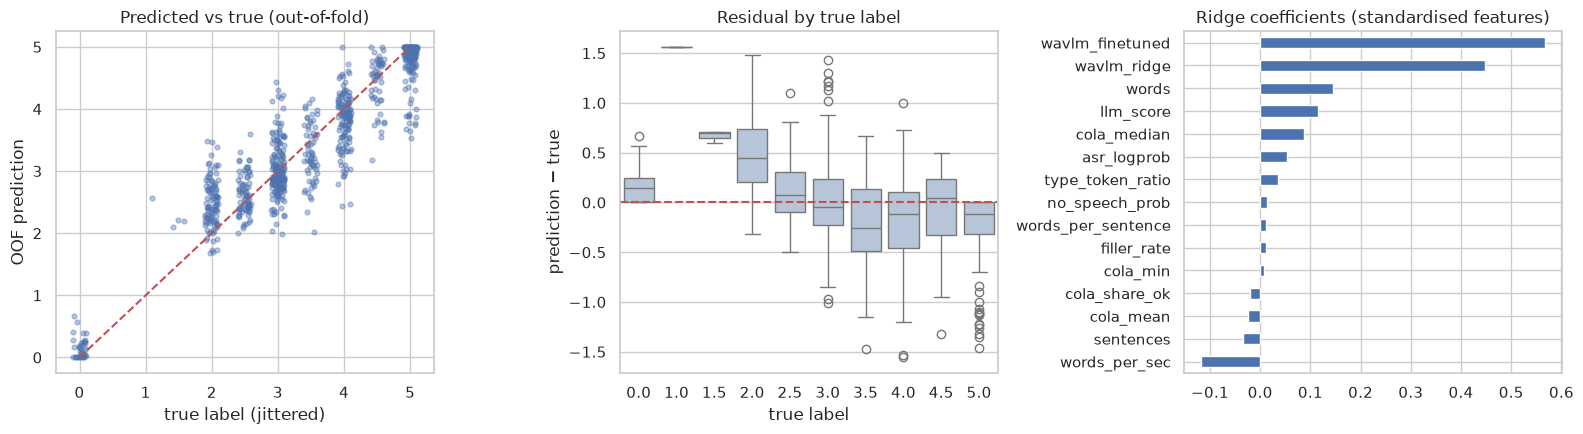

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(y + np.random.uniform(-.1, .1, len(y)), oof_final, alpha=.4, s=12)
ax[0].plot([0, 5], [0, 5], 'r--'); ax[0].set(xlabel='true label (jittered)', ylabel='OOF prediction', title='Predicted vs true (out-of-fold)')
res = oof_final - y
sns.boxplot(x=y, y=res, ax=ax[1], color='lightsteelblue'); ax[1].axhline(0, color='r', ls='--'); ax[1].set(title='Residual by true label', xlabel='true label', ylabel='prediction − true')
coef = pd.Series(final_ridge[-1].coef_, index=cols).sort_values()
coef.plot.barh(ax=ax[2], title='Ridge coefficients (standardised features)')
plt.tight_layout(); plt.show()

**Reading the plots.** Predictions track the labels closely through the 2–5 range. As usual for regression they shrink toward the mean: the lowest labels are over-predicted and 5s are under-predicted. The largest coefficients belong to the two audio features and the LLM judge, which matches the ablation table: each new view of the data (fluency → grammaticality → rubric judgement → acoustics) lowers RMSE.

## 7. Submission

In [10]:
pred = np.clip((final_ridge.predict(F_te[cols]) + final_gbm.predict(F_te[cols])) / 2, 0, 5)
sub = pd.DataFrame({'filename': te.filename, 'label': pred})
assert len(sub) == 216 and sub.label.between(0, 5).all()
sub.to_csv('submission.csv', index=False)
sub.describe()

,label
count,216.000000
mean,3.266871
std,0.839179
min,1.867918
25%,2.574587
50%,3.114167
75%,3.776566
max,5.000000


## 8. Limitations and next steps
- **ASR smooths grammar.** Whisper silently fixes some errors, so text features under-penalise weaker speakers. The audio features partly compensate.
- **Small data.** 769 clips: every model choice was kept simple and checked with cross-validation rather than the public leaderboard (about 130 clips, noisy).
- **LLM judge reproducibility.** See Section 4. The prompt and code are in the repo.
- **Tried and dropped:** fine-tuning WavLM-large (on a 12 GB GPU it only fit batch size 2 and scored worse per fold than base-plus) and averaging two fine-tuning seeds (no CV gain).
- **Next:** WavLM-large on a bigger GPU, and an ASR setting that keeps disfluencies verbatim.